In [12]:
import torch
import pandas as pd
import numpy as np
from tqdm import tqdm

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

from paths import path_to_tiles_metadata_EAGLE_2016
from paths import path_to_tiles_tensor_EAGLE_2016

# DINOv2

In [2]:
model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')  # also vits14, vitl14, vitg14
model.eval()

Using cache found in /Users/kim.bente/.cache/torch/hub/facebookresearch_dinov2_main
/Users/kim.bente/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/kim.bente/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/kim.bente/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


DinoVisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (blocks): ModuleList(
    (0-11): 12 x NestedTensorBlock(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
      (attn): MemEffAttention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
      (ls2): LayerScale()
      (drop_path2): Identity()
    )
  )
  (norm): LayerNorm((768,), eps=1

In [10]:
tiles = torch.load(path_to_tiles_tensor_EAGLE_2016)
# Create a new tensor with 3 channels by repeating the original tensor along the channel dimension
tiles_3C = tiles.repeat(1, 3, 1, 1) 
print(f"Shape of tiles tensor: {tiles_3C.shape}")

meta = pd.read_csv(path_to_tiles_metadata_EAGLE_2016)

Shape of tiles tensor: torch.Size([636, 3, 336, 336])


# Batched inference

In [5]:
RERUN_INFERENCE = False

if RERUN_INFERENCE == True:
    batch_size = 32 
    # around 3.5 minutes for 600 tiles

    embeddings = []
    with torch.inference_mode():
        for i in tqdm(range(0, len(tiles_3C), batch_size)):
            batch = tiles_3C[i : i + batch_size]
            out = model(batch)             
            embeddings.append(out.cpu())        

    embeddings = torch.cat(embeddings, dim = 0) 
    torch.save(embeddings, "embeddings/dinov2_embeddings_EAGLE_2016.pt")

else:
    embeddings = torch.load("embeddings/dinov2_embeddings_EAGLE_2016.pt")

In [6]:
embeddings

tensor([[ 1.3777,  2.1052,  1.3096,  ..., -2.5854, -0.4936, -0.9519],
        [ 1.4158,  2.1037,  1.2755,  ..., -2.5895, -0.4630, -0.9728],
        [ 1.4414,  2.1243,  1.2589,  ..., -2.6511, -0.3628, -1.0053],
        ...,
        [ 1.3293,  2.0754,  1.3842,  ..., -2.4959, -0.6966, -0.8926],
        [ 1.3527,  2.1095,  1.3391,  ..., -2.5632, -0.5828, -0.9189],
        [ 1.5244,  2.1973,  1.2057,  ..., -2.7081, -0.2573, -1.0643]])

# TSNE

In [20]:
xy = TSNE(
    n_components = 2,
    perplexity = 20,        
    metric = "cosine",
    init = "pca",
    learning_rate = "auto",
    random_state = 42,
).fit_transform(embeddings)

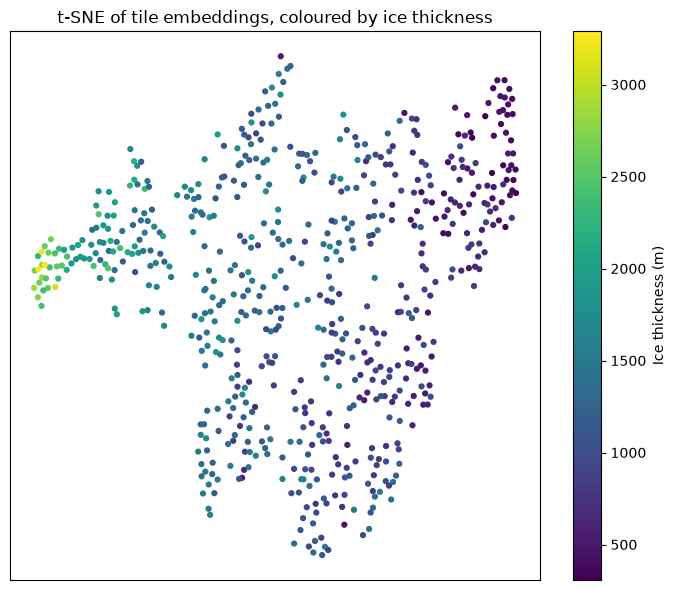

In [22]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["ice_thickness"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Ice thickness (m)")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

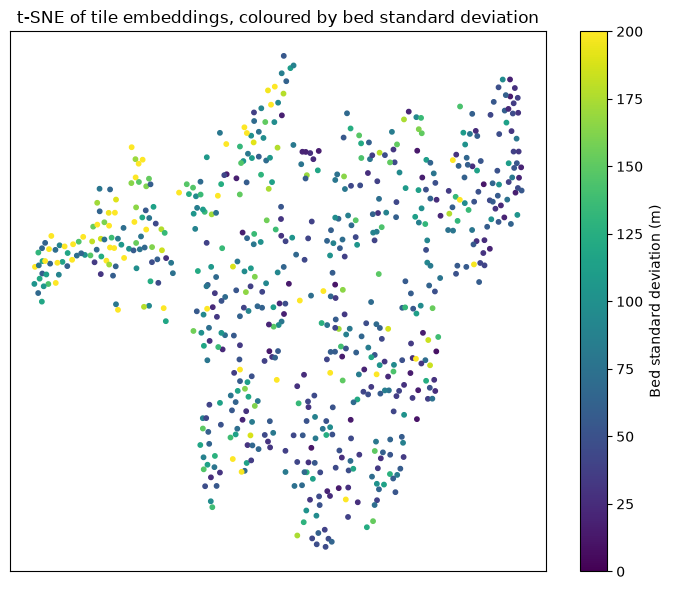

In [27]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["bed_std_m"], cmap = "viridis", s = 10, vmin = 0, vmax = 200)
fig.colorbar(sc, ax = ax, label = "Bed standard deviation (m)")
ax.set_title("t-SNE of tile embeddings, coloured by bed standard deviation")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

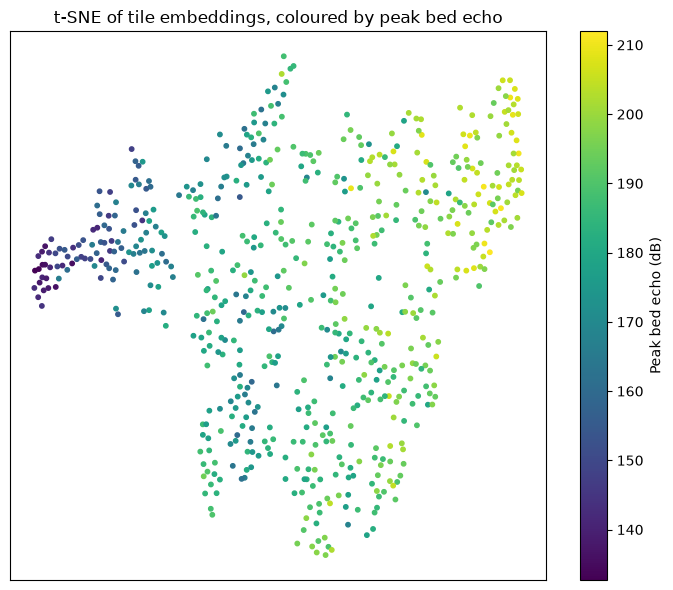

In [29]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["peak_bed_echo_db"], cmap = "viridis", s = 10)
fig.colorbar(sc, ax = ax, label = "Peak bed echo (dB)")
ax.set_title("t-SNE of tile embeddings, coloured by peak bed echo")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

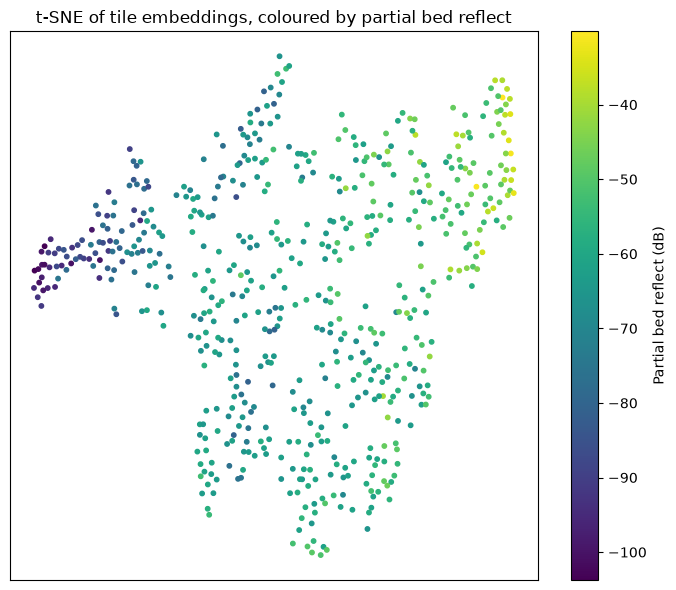

In [32]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["partial_bed_reflect"], cmap = "viridis", s = 10)
fig.colorbar(sc, ax = ax, label = "Partial bed reflect (dB)")
ax.set_title("t-SNE of tile embeddings, coloured by partial bed reflect")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

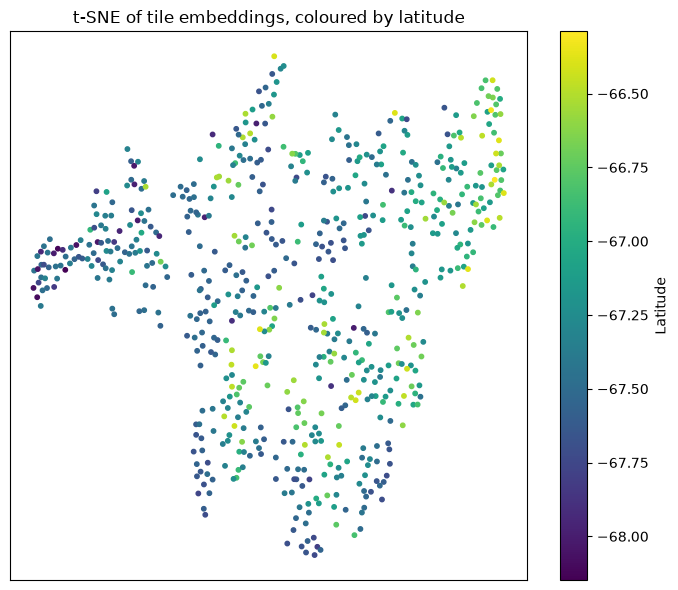

In [34]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["LAT"], cmap = "viridis", s = 10)
fig.colorbar(sc, ax = ax, label = "Latitude")
ax.set_title("t-SNE of tile embeddings, coloured by latitude")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [30]:
meta

,granule_id,flight,x_center_idx,y_center_idx,tile_id,X,Y,LON,LAT,bed_elevation,surface_elevation,ice_thickness,partial_bed_reflect,srf_reflect,tile_along_track_span_m,tile_vertical_span_m,bed_std_m,peak_bed_echo_db
0,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000,ICP8/F07,168,1054,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000_0168,2.233971e+06,-1.003400e+06,114.187485,-67.733750,-364.43,774.85,1139.28,-51.14,-13.08,6386.525126,-567.550895,45.556204,196.545
1,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000,ICP8/F07,840,1022,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000_0840,2.300701e+06,-8.993874e+05,111.351460,-67.544975,-234.70,960.39,1195.09,NaN,-13.48,5963.723460,-567.550741,41.048903,186.433
2,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,168,1111,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0168,2.311783e+06,-9.074552e+05,111.431730,-67.427400,-461.39,803.03,1264.42,-61.86,-32.32,7788.083221,-567.550741,134.157683,178.590
3,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,504,1021,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0504,2.309200e+06,-9.009693e+05,111.313995,-67.469670,-309.08,815.82,1124.90,-48.56,-13.35,6817.404817,-567.550972,95.571549,199.023
4,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,840,1038,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0840,2.303299e+06,-9.004596e+05,111.352684,-67.520050,-305.99,893.33,1199.32,NaN,-29.01,5881.549013,-567.550972,65.878738,183.386
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,1512,1274,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_1512,2.522422e+06,-4.521052e+05,100.161400,-66.726880,-1013.32,613.75,1627.07,NaN,-9.85,7327.740001,-567.550741,111.406558,169.304
632,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,2520,1000,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_2520,2.514960e+06,-4.314182e+05,99.733760,-66.823494,-575.99,535.73,1111.72,NaN,-8.17,7712.768837,-567.550895,51.215338,181.451
633,ER2HI1B_2017034_DEN_JKB2r_Y50a_000,ICP8/F14,3528,523,ER2HI1B_2017034_DEN_JKB2r_Y50a_000_3528,2.507020e+06,-4.098388e+05,99.284240,-66.924330,229.01,592.25,363.24,-46.89,-6.96,7165.212069,-567.550665,49.764983,205.953
634,ER2HI1B_2017034_DEN_JKB2r_Y50a_001,ICP8/F14,168,701,ER2HI1B_2017034_DEN_JKB2r_Y50a_001_0168,2.502582e+06,-3.979182e+05,99.034550,-66.979920,240.07,858.46,618.38,NaN,-11.60,6643.045015,-567.550665,34.648211,187.294
